# Hidden-state directions for ParaDetox

This notebook asks whether Qwen2.5-0.5B-Instruct contains a stable linear direction from toxic text toward its neutral ParaDetox rewrite. It estimates directions only on an extraction split and evaluates them on unseen toxic-source groups at every representation depth using both mean and final-token pooling.

In [1]:
from pathlib import Path
import gc
import math
import time

from datasets import load_dataset
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from transformers import AutoModelForCausalLM, AutoTokenizer

PROJECT_ROOT = next(
    (parent for parent in [Path.cwd(), *Path.cwd().parents] if (parent / "pyproject.toml").is_file()),
    Path.cwd(),
)
ARTIFACT_DIRECTORY = PROJECT_ROOT / "steering_experimentation/artifacts"
ARTIFACT_DIRECTORY.mkdir(parents=True, exist_ok=True)

MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"
DATASET_ID = "s-nlp/paradetox"
SOURCE_COLUMN = "en_toxic_comment"
TARGET_COLUMN = "en_neutral_comment"
SEED = 42
EXTRACTION_PAIRS = 8_000
HELDOUT_PAIRS = 2_000
BATCH_SIZE = 32
MAX_LENGTH = 128
NUMBER_OF_SHUFFLED_CONTROLS = 10

device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float16 if device.type in {"mps", "cuda"} else torch.float32
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=dtype).to(device)
model.eval()
config = model.config
print("Device:", device, "layers:", config.num_hidden_layers, "hidden size:", config.hidden_size)

/Users/nandanprince/Desktop/NLP_project/SecondThought/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: mps layers: 24 hidden size: 896


## 1. Construct leakage-safe extraction and held-out splits

Only one neutral rewrite is retained per normalized toxic source. Exact copies are excluded, and the source groups used for direction estimation never appear in held-out evaluation.

In [2]:
def normalize_text(text):
    return " ".join(str(text).split()).casefold()

raw = load_dataset(DATASET_ID, split="train")
pairs = raw.select_columns([SOURCE_COLUMN, TARGET_COLUMN]).to_pandas().rename(
    columns={SOURCE_COLUMN: "toxic", TARGET_COLUMN: "neutral"}
)
pairs["toxic"] = pairs["toxic"].fillna("").str.strip()
pairs["neutral"] = pairs["neutral"].fillna("").str.strip()
pairs["toxic_key"] = pairs["toxic"].map(normalize_text)
pairs["neutral_key"] = pairs["neutral"].map(normalize_text)
pairs = pairs.loc[(pairs["toxic"] != "") & (pairs["neutral"] != "")]
pairs = pairs.loc[pairs["toxic_key"] != pairs["neutral_key"]]
pairs = pairs.drop_duplicates(["toxic_key", "neutral_key"])
pairs = (
    pairs.sample(frac=1, random_state=SEED)
    .drop_duplicates("toxic_key")
    .sort_values("toxic_key")
    .reset_index(drop=True)
)

required = EXTRACTION_PAIRS + HELDOUT_PAIRS
if len(pairs) < required:
    raise ValueError(f"Need {required:,} unique non-copy sources; found {len(pairs):,}")
rng = np.random.default_rng(SEED)
positions = rng.permutation(len(pairs))[:required]
extraction_pairs = pairs.iloc[positions[:EXTRACTION_PAIRS]].reset_index(drop=True)
heldout_pairs = pairs.iloc[positions[EXTRACTION_PAIRS:]].reset_index(drop=True)
assert set(extraction_pairs["toxic_key"]).isdisjoint(heldout_pairs["toxic_key"])

split_frame = pd.concat([
    extraction_pairs.assign(split="extraction"),
    heldout_pairs.assign(split="heldout"),
], ignore_index=True)
SPLIT_PATH = ARTIFACT_DIRECTORY / "paradetox_direction_pairs.csv"
split_frame[["split", "toxic_key", "toxic", "neutral"]].to_csv(SPLIT_PATH, index=False)
print({"extraction": len(extraction_pairs), "heldout": len(heldout_pairs)})
print("Saved split:", SPLIT_PATH)

{'extraction': 8000, 'heldout': 2000}
Saved split: /Users/nandanprince/Desktop/NLP_project/SecondThought/steering_experimentation/artifacts/paradetox_direction_pairs.csv


## 2. Collect paired differences at every depth

For each pair and layer, the direction contribution is `neutral representation − toxic representation`. Mean pooling summarizes all non-padding tokens. Final-token pooling uses the last real token, which can attend to the full preceding sentence in a causal decoder.

In [3]:
def mean_pool(hidden, attention_mask):
    mask = attention_mask.unsqueeze(-1).to(hidden.dtype)
    return (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp_min(1)

def final_token_pool(hidden, attention_mask):
    positions = attention_mask.sum(dim=1) - 1
    batch = torch.arange(hidden.shape[0], device=hidden.device)
    return hidden[batch, positions]

def collect_deltas(frame, split_name):
    pair_count = len(frame)
    depth_count = config.num_hidden_layers + 1
    deltas = torch.empty((2, pair_count, depth_count, config.hidden_size), dtype=torch.float16)
    truncated = 0
    started = time.perf_counter()
    for batch_number, start in enumerate(range(0, pair_count, BATCH_SIZE), start=1):
        stop = min(start + BATCH_SIZE, pair_count)
        batch = frame.iloc[start:stop]
        size = len(batch)
        texts = batch["toxic"].tolist() + batch["neutral"].tolist()
        lengths = tokenizer(texts, padding=False, truncation=False)["input_ids"]
        truncated += sum(len(ids) > MAX_LENGTH for ids in lengths)
        encoded = tokenizer(texts, padding=True, truncation=True, max_length=MAX_LENGTH, return_tensors="pt")
        inputs = {name: tensor.to(device) for name, tensor in encoded.items()}
        with torch.inference_mode():
            outputs = model.model(**inputs, output_hidden_states=True, use_cache=False, return_dict=True)
        mask = inputs["attention_mask"]
        for depth, hidden in enumerate(outputs.hidden_states):
            mean = mean_pool(hidden, mask)
            final = final_token_pool(hidden, mask)
            deltas[0, start:stop, depth] = (mean[size:] - mean[:size]).cpu().to(torch.float16)
            deltas[1, start:stop, depth] = (final[size:] - final[:size]).cpu().to(torch.float16)
        if batch_number == 1 or batch_number % 25 == 0 or stop == pair_count:
            print(f"{split_name}: {stop:,}/{pair_count:,} pairs, {time.perf_counter()-started:.1f}s")
    return deltas, truncated

extraction_deltas, extraction_truncated = collect_deltas(extraction_pairs, "extraction")
heldout_deltas, heldout_truncated = collect_deltas(heldout_pairs, "heldout")
print("Shapes:", tuple(extraction_deltas.shape), tuple(heldout_deltas.shape))
print("Truncated sentences:", extraction_truncated + heldout_truncated)

extraction: 32/8,000 pairs, 0.4s


extraction: 800/8,000 pairs, 7.0s


extraction: 1,600/8,000 pairs, 13.9s


extraction: 2,400/8,000 pairs, 20.8s


extraction: 3,200/8,000 pairs, 27.4s


...

extraction: 8,000/8,000 pairs, 68.3s


heldout: 32/2,000 pairs, 0.3s


heldout: 800/2,000 pairs, 6.9s


heldout: 1,600/2,000 pairs, 13.8s


heldout: 2,000/2,000 pairs, 17.3s
Shapes: (2, 8000, 25, 896) (2, 2000, 25, 896)
Truncated sentences: 0


## 3. Evaluate every layer and pooling method

The main metric is held-out pair ordering: the fraction of unseen pairs whose neutral-minus-toxic difference has positive projection onto the extraction direction. Chance is approximately 50%. Split-half cosine measures reproducibility, while balanced shuffled-label directions provide an empirical null control.

In [4]:
half_assignment = np.zeros(len(extraction_pairs), dtype=np.int8)
half_assignment[rng.permutation(len(extraction_pairs))[len(extraction_pairs)//2:]] = 1

base_signs = np.ones(len(extraction_pairs), dtype=np.float32)
base_signs[:len(base_signs)//2] = -1
shuffled_signs = torch.stack([
    torch.from_numpy(rng.permutation(base_signs).copy())
    for _ in range(NUMBER_OF_SHUFFLED_CONTROLS)
])

rows = []
for pooling_index, pooling_name in enumerate(["mean", "final_token"]):
    for depth in range(config.num_hidden_layers + 1):
        extraction = extraction_deltas[pooling_index, :, depth].float()
        heldout = heldout_deltas[pooling_index, :, depth].float()
        mean_delta = extraction.mean(dim=0)
        direction = mean_delta / mean_delta.norm().clamp_min(1e-12)
        gaps = heldout @ direction
        accuracy = (gaps > 0).float().mean().item()
        se = math.sqrt(accuracy * (1 - accuracy) / len(gaps))
        gap_std = gaps.std(unbiased=True).item()
        heldout_norm = heldout.norm(dim=1)
        cosines = gaps[heldout_norm > 0] / heldout_norm[heldout_norm > 0]

        half_directions = []
        for half in (0, 1):
            vector = extraction[half_assignment == half].mean(dim=0)
            half_directions.append(vector / vector.norm().clamp_min(1e-12))
        split_half = F.cosine_similarity(half_directions[0], half_directions[1], dim=0).item()

        shuffled_means = (shuffled_signs @ extraction) / len(extraction)
        shuffled_directions = shuffled_means / shuffled_means.norm(dim=1, keepdim=True).clamp_min(1e-12)
        shuffled_accuracy = ((shuffled_directions @ heldout.T) > 0).float().mean(dim=1)

        if depth == 0:
            location = "embedding output"
        elif depth == config.num_hidden_layers:
            location = "final normalized output"
        else:
            location = f"after decoder layer {depth - 1}"
        rows.append({
            "pooling": pooling_name,
            "hidden_state_index": depth,
            "location": location,
            "raw_direction_norm": mean_delta.norm().item(),
            "heldout_ordering_accuracy": accuracy,
            "accuracy_95ci_low": max(0, accuracy - 1.96 * se),
            "accuracy_95ci_high": min(1, accuracy + 1.96 * se),
            "projection_effect_size": gaps.mean().item() / gap_std if gap_std else np.nan,
            "mean_heldout_delta_cosine": cosines.mean().item(),
            "median_heldout_delta_cosine": cosines.median().item(),
            "split_half_direction_cosine": split_half,
            "shuffled_accuracy_mean": shuffled_accuracy.mean().item(),
            "shuffled_accuracy_max": shuffled_accuracy.max().item(),
            "accuracy_above_shuffle_mean": accuracy - shuffled_accuracy.mean().item(),
        })

layer_results = pd.DataFrame(rows)
RESULTS_PATH = ARTIFACT_DIRECTORY / "paradetox_layer_results.csv"
layer_results.to_csv(RESULTS_PATH, index=False)
display(layer_results.round(4))
print("Saved results:", RESULTS_PATH)

,pooling,hidden_state_index,location,raw_direction_norm,heldout_ordering_accuracy,accuracy_95ci_low,accuracy_95ci_high,projection_effect_size,mean_heldout_delta_cosine,median_heldout_delta_cosine,split_half_direction_cosine,shuffled_accuracy_mean,shuffled_accuracy_max,accuracy_above_shuffle_mean
0,mean,0,embedding output,0.0382,0.9740,0.9670,0.9810,1.3927,0.3536,0.3516,0.9979,0.3789,0.6935,0.5951
1,mean,1,after decoder layer 0,0.5764,0.9965,0.9939,0.9991,1.6821,0.4225,0.4327,0.9988,0.3449,0.6675,0.6517
2,mean,2,after decoder layer 1,0.7910,0.9940,0.9906,0.9974,1.6657,0.4069,0.4210,0.9987,0.4103,0.8245,0.5838
3,mean,3,after decoder layer 2,21.8423,0.8900,0.8763,0.9037,0.5838,0.7236,0.9871,1.0000,0.4243,0.8615,0.4657
4,mean,4,after decoder layer 3,44.9941,0.8900,0.8763,0.9037,0.5674,0.7384,0.9959,1.0000,0.3472,0.8650,0.5428
5,mean,5,after decoder layer 4,45.0462,0.8895,0.8758,0.9032,0.5676,0.7364,0.9947,1.0000,0.3479,0.8670,0.5416
6,mean,6,after decoder layer 5,45.7378,0.8925,0.8789,0.9061,0.5674,0.7357,0.9943,1.0000,0.3446,0.8780,0.5479
7,mean,7,after decoder layer 6,45.7773,0.8940,0.8805,0.9075,0.5675,0.7359,0.9938,1.0000,0.3425,0.8860,0.5515
8,mean,8,after decoder layer 7,45.7556,0.8920,0.8784,0.9056,0.5670,0.7343,0.9934,1.0000,0.3441,0.8785,0.5479
9,mean,9,after decoder layer 8,45.8024,0.8930,0.8795,0.9065,0.5671,0.7338,0.9928,1.0000,0.3432,0.8800,0.5498


Saved results: /Users/nandanprince/Desktop/NLP_project/SecondThought/steering_experimentation/artifacts/paradetox_layer_results.csv


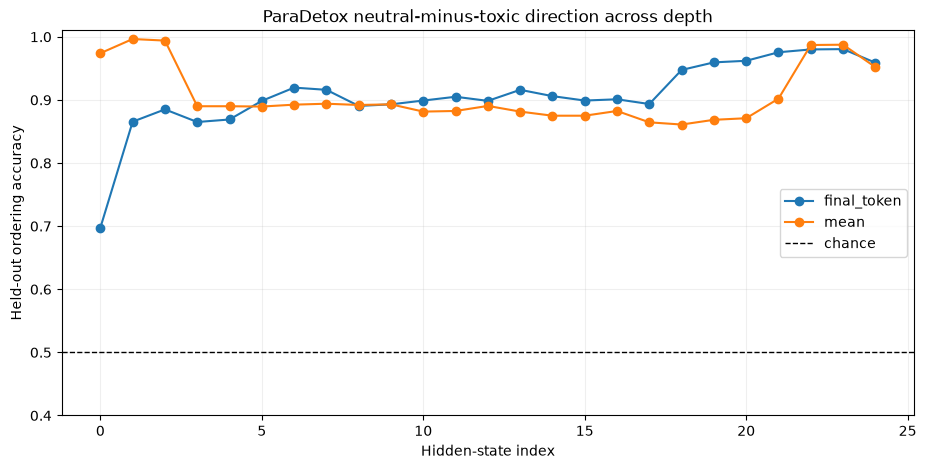

In [5]:
fig, ax = plt.subplots(figsize=(11, 5))
for pooling, group in layer_results.groupby("pooling"):
    ax.plot(group["hidden_state_index"], group["heldout_ordering_accuracy"], marker="o", label=pooling)
ax.axhline(.5, color="black", linestyle="--", linewidth=1, label="chance")
ax.set(xlabel="Hidden-state index", ylabel="Held-out ordering accuracy", ylim=(0.4, 1.01), title="ParaDetox neutral-minus-toxic direction across depth")
ax.legend()
ax.grid(alpha=.2)
plt.show()

## 4. Select causal-intervention candidates and save the artifact

The best hookable mean-pooled and final-token directions are saved, together with Layer 11 mean pooling for comparison and a balanced shuffled-label control at the primary layer. The final normalized output is excluded because it is not the direct output of a decoder block hook.

In [6]:
hookable = layer_results.loc[
    layer_results["hidden_state_index"].between(1, config.num_hidden_layers - 1)
].copy()
best_mean = hookable.loc[hookable.query("pooling == 'mean'")["heldout_ordering_accuracy"].idxmax()]
best_final = hookable.loc[hookable.query("pooling == 'final_token'")["heldout_ordering_accuracy"].idxmax()]
layer11 = hookable.loc[(hookable["pooling"] == "mean") & (hookable["hidden_state_index"] == 12)].iloc[0]

selected_rows = {
    "best_mean": best_mean,
    "best_final": best_final,
    "layer11_mean": layer11,
}
candidates = {}
raw_directions = {}
for key, row in selected_rows.items():
    pooling_index = 0 if row["pooling"] == "mean" else 1
    depth = int(row["hidden_state_index"])
    raw = extraction_deltas[pooling_index, :, depth].float().mean(dim=0)
    candidates[key] = {
        "layer_index": depth - 1,
        "hidden_state_index": depth,
        "pooling": row["pooling"],
        "heldout_ordering_accuracy": float(row["heldout_ordering_accuracy"]),
        "projection_effect_size": float(row["projection_effect_size"]),
        "raw_direction_norm": float(raw.norm()),
        "is_control": False,
    }
    raw_directions[key] = raw.cpu()

control_signs = torch.from_numpy(rng.permutation(base_signs).copy())
for learned_key, row in selected_rows.items():
    pooling_index = 0 if row["pooling"] == "mean" else 1
    depth = int(row["hidden_state_index"])
    extraction = extraction_deltas[pooling_index, :, depth].float()
    heldout = heldout_deltas[pooling_index, :, depth].float()
    control_raw = (control_signs @ extraction) / len(extraction)
    control_direction = control_raw / control_raw.norm().clamp_min(1e-12)
    control_key = f"shuffled_{learned_key}"
    candidates[control_key] = {
        "layer_index": depth - 1,
        "hidden_state_index": depth,
        "pooling": row["pooling"],
        "heldout_ordering_accuracy": float(((heldout @ control_direction) > 0).float().mean()),
        "projection_effect_size": None,
        "raw_direction_norm": float(control_raw.norm()),
        "is_control": True,
        "control_for": learned_key,
    }
    raw_directions[control_key] = control_raw.cpu()

ARTIFACT_PATH = ARTIFACT_DIRECTORY / "qwen2_5_0_5b_paradetox_directions.pt"
torch.save({
    "model_id": MODEL_ID,
    "dataset_id": DATASET_ID,
    "direction_semantics": "neutral_minus_toxic",
    "seed": SEED,
    "extraction_pairs": len(extraction_pairs),
    "heldout_pairs": len(heldout_pairs),
    "candidates": candidates,
    "raw_directions": raw_directions,
}, ARTIFACT_PATH)

display(pd.DataFrame(candidates).T)
print("Saved steering artifact:", ARTIFACT_PATH)

,layer_index,hidden_state_index,pooling,heldout_ordering_accuracy,projection_effect_size,raw_direction_norm,is_control,control_for
best_mean,0,1,mean,0.9965,1.682054,0.576379,False,NaN
best_final,22,23,final_token,0.9805,1.604055,13.109015,False,NaN
layer11_mean,11,12,mean,0.8905,0.567295,45.943142,False,NaN
shuffled_best_mean,0,1,mean,0.622,None,0.014503,True,best_mean
shuffled_best_final,22,23,final_token,0.9015,None,0.325137,True,best_final
shuffled_layer11_mean,11,12,mean,0.884,None,0.91969,True,layer11_mean


Saved steering artifact: /Users/nandanprince/Desktop/NLP_project/SecondThought/steering_experimentation/artifacts/qwen2_5_0_5b_paradetox_directions.pt


## Interpretation checklist

A credible ParaDetox direction should substantially exceed both 50% and the shuffled controls on unseen toxic sources, show a positive effect size, and remain stable across extraction halves. Even a strong result is correlational: the direction may combine toxicity removal with politeness, lexical substitution, grammar, and length. The activation-steering notebook tests whether adding the frozen vector causally reduces output toxicity while preserving meaning and critical values.

## Results report

The large-scale experiment used 8,000 unique toxic sources for extraction and 2,000 source-disjoint pairs for held-out evaluation. Each source contributed only one neutral rewrite, preventing repeated ParaDetox paraphrases from leaking across splits.

| Candidate | Pooling | Raw norm | Held-out ordering | Effect size | Split-half cosine |
|---|---|---:|---:|---:|---:|
| After decoder Layer 0 | Mean | 0.576 | **99.65%** | **1.682** | 0.9988 |
| After decoder Layer 22 | Final token | 13.109 | **98.05%** | **1.604** | 0.9988 |
| After decoder Layer 11 | Mean | 45.943 | **89.05%** | 0.567 | approximately 1.0 |

These results provide strong evidence that Qwen contains reproducible linear components aligned with ParaDetox's neutral-minus-toxic transformation. The earliest contextual mean representation is the strongest pair-ordering probe, while late final-token representations are also highly discriminative. Layer 11 is substantially stronger for ParaDetox than it was for GYAFC formality.

The raw vector norms differ by almost two orders of magnitude. Therefore, equal raw alpha values would not be a fair cross-layer comparison: at alpha 0.5, Layer 11 would receive a shift norm around 22.97 while Layer 0 would receive only 0.29. The causal notebook uses unit-normalized directions by default so alpha controls the same intervention norm for every candidate. Raw vectors remain saved in the artifact for experiments that intentionally reproduce the average paired displacement.

The geometric result does not prove pure toxicity localization. ParaDetox rewrites also alter politeness, grammar, length, and lexical choice. Causal steering must be validated with independent toxicity, semantic-similarity, critical-value, and qualitative failure analysis.

### Control interpretation after causal testing

The representation results identify where toxic and neutral examples are linearly separable, but they do not by themselves prove that adding the estimated vector will causally detoxify generation. The matched intervention controls make this distinction visible:

- **Layer 22 final-token** retained a positive detoxification effect that its matched shuffled direction did not reproduce, making it the strongest causal candidate.
- **Layer 0 mean-pooled** had the best held-out ordering score, yet a shuffled vector caused an equal or larger toxicity reduction. Its geometric result is real, but its generation effect is not shown to be direction-specific.
- **Layer 11 mean-pooled** behaved almost identically to its matched shuffled control during generation, so it should not be interpreted as a learned detoxification direction.

This is why candidate selection must combine held-out geometry, several shuffled controls, and an alpha-sweep intervention test rather than choosing the largest separation score alone.
